# EDA

#### Dependencias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Lectura

In [2]:
df = pd.read_csv("../data/processed/smoking_train_corregido.csv")
df.shape 

(50000, 27)

#### Variable objetivo

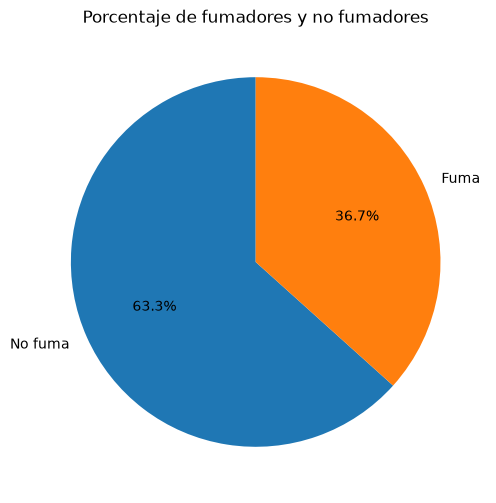

In [3]:
plt.figure(figsize=(8,6))
conteo_smoking = df.smoking.value_counts()
plt.pie(conteo_smoking, labels=["No fuma", "Fuma"], autopct="%1.1f%%", startangle=90)
plt.title("Porcentaje de fumadores y no fumadores")
plt.show()

El 36,7% fuma y el 63,3% no. Hay más no fumadores.

#### Variables categóricas vs smoking

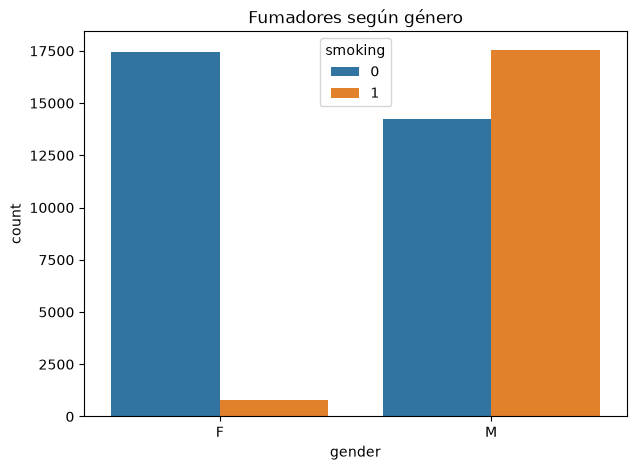

In [4]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="gender", hue="smoking")
plt.title("Fumadores según género")
plt.show()

In [5]:
pd.crosstab(df["gender"], df["smoking"], normalize="index") * 100 # % de fumadores dentro de cada género

smoking,0,1
gender,,
F,95.723540,4.276460
M,44.783539,55.216461


Los hombres son los que mas fuman, el 55,2% de hombres fuma vs solo el 4,3% de las mujeres. El género será una variable importante para el modelo.

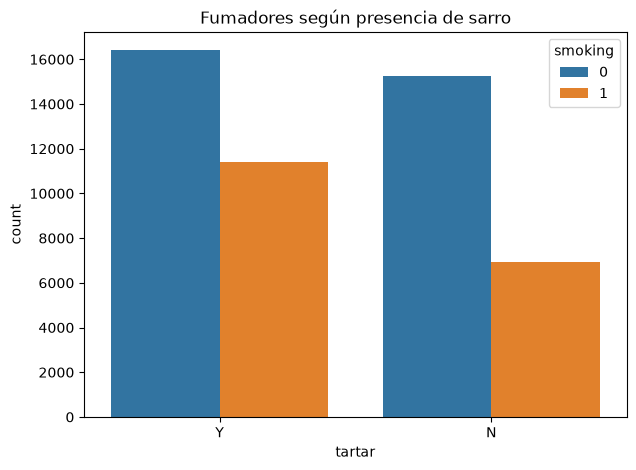

In [6]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="tartar", hue="smoking")
plt.title("Fumadores según presencia de sarro")
plt.show()

In [7]:
pd.crosstab(df["tartar"], df["smoking"], normalize="index") * 100

smoking,0,1
tartar,,
N,68.740714,31.259286
Y,59.026953,40.973047


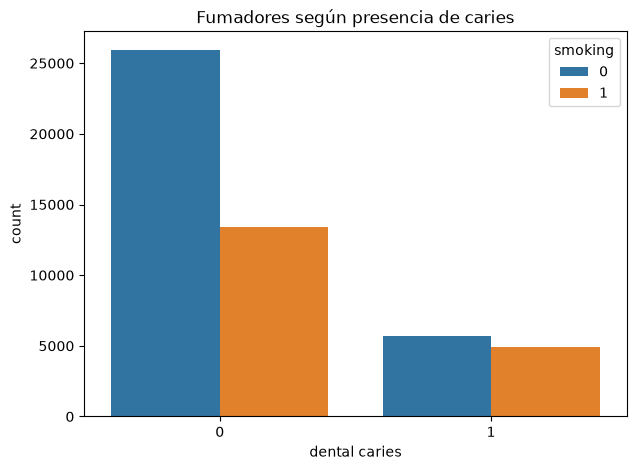

In [8]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="dental caries", hue="smoking")
plt.title("Fumadores según presencia de caries")
plt.show()

In [9]:
pd.crosstab(df["dental caries"], df["smoking"], normalize="index") * 100

smoking,0,1
dental caries,,
0,65.943981,34.056019
1,53.734985,46.265015


Los que tienen sarro o caries fuman un poco mas (41% y 46%), que quienes no (31% y 34%). Tiene sentido porque fumar afecta los dientes, pero la diferencia es mucho menor que con el género.

#### Variables numéricas vs smoking

In [10]:
df.drop(columns=["ID"]).corr(numeric_only=True)["smoking"].sort_values() # correlación de cada variable con smoking

HDL                   -0.176993
age                   -0.163722
LDL                   -0.045706
Cholesterol           -0.030030
hearing(left)         -0.021871
hearing(right)        -0.017727
Urine protein          0.015284
AST                    0.057348
eyesight(left)         0.061086
eyesight(right)        0.062513
systolic               0.073225
ALT                    0.094137
fasting blood sugar    0.098124
dental caries          0.103757
relaxation             0.108155
serum creatinine       0.214941
waist(cm)              0.224883
Gtp                    0.235980
triglyceride           0.251116
weight(kg)             0.301405
height(cm)             0.396284
hemoglobin             0.400333
smoking                1.000000
Name: smoking, dtype: float64

Las variables más relacionadas con fumar son la hemoglobina (0,40), la altura (0,40) y el peso (0,30). Las tres suelen ser más altas en hombres, así que puede que en parte reflejen el género. Con signo negativo están el HDL (colesterol bueno) y la edad: los fumadores tienden a tener menos HDL y a ser más jóvenes.

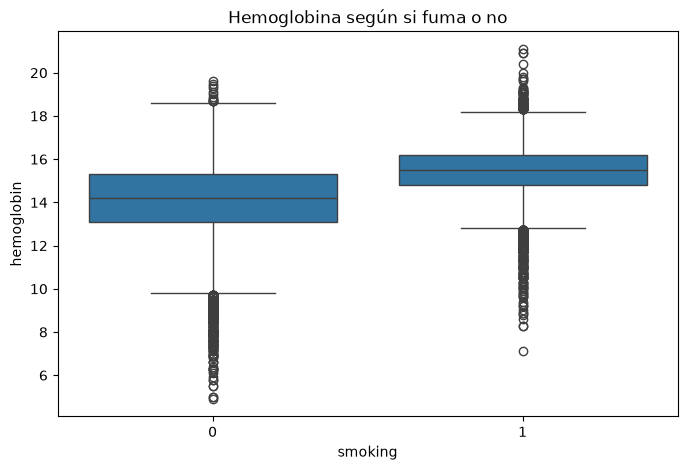

In [11]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="smoking", y="hemoglobin")
plt.title("Hemoglobina según si fuma o no")
plt.show()

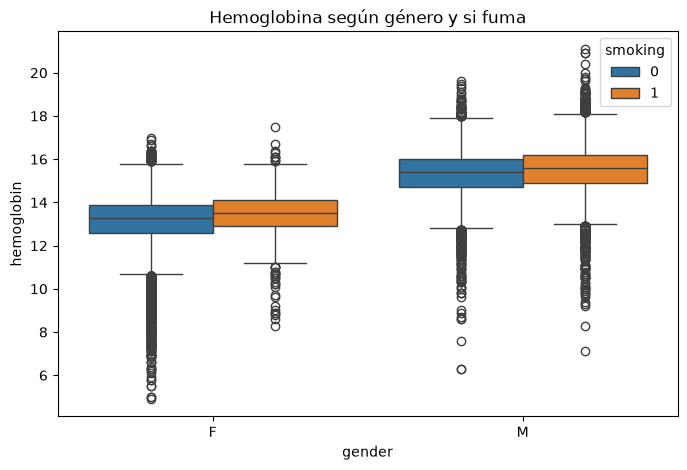

In [12]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="gender", y="hemoglobin", hue="smoking")
plt.title("Hemoglobina según género y si fuma")
plt.show()

En el primer gráfico los fumadores tienen más hemoglobina. Pero al separar por género, la diferencia casi desaparece: dentro de hombres y dentro de mujeres, fumadores y no fumadores tienen valores muy parecidos. La hemoglobina parecía relacionada con fumar porque la mayoría de los fumadores son hombres, y los hombres tienen más hemoglobina. Con la altura y el peso seguramente pasa lo mismo.

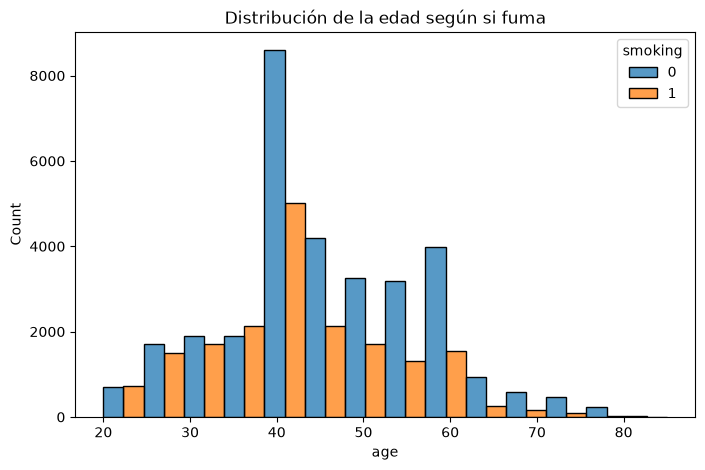

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="age", hue="smoking", bins=14, multiple="dodge")
plt.title("Distribución de la edad según si fuma")
plt.show()

In [14]:
pd.crosstab(df["age"], df["gender"]) # cantidad de hombres y mujeres en cada edad

gender,F,M
age,,
20,4,1426
25,6,3199
30,2,3621
35,0,4024
40,6475,7129
45,3221,3107
50,2415,2554
55,2290,2218
60,2678,2853


In [15]:
df.groupby("age")["smoking"].mean() * 100 # % de fumadores en cada edad

age
20    51.468531
25    46.489860
30    47.364063
35    53.006958
40    36.827404
45    33.802149
50    34.232240
55    29.325643
60    27.879226
65    22.314738
70    20.320856
75    16.216216
80    11.153846
85     7.142857
Name: smoking, dtype: float64

Los más jóvenes parecen fumar más: cerca del 50% entre los 20 y 35 años, contra 37% a los 40 y menos con más edad. Antes de los 40 casi no hay mujeres en el dataset (12 mujeres contra más de 12.000 hombres), así que el grupo joven es casi todo de hombres, que son los que más fuman. El género explica buena parte de la diferencia.

#### Valores atípicos

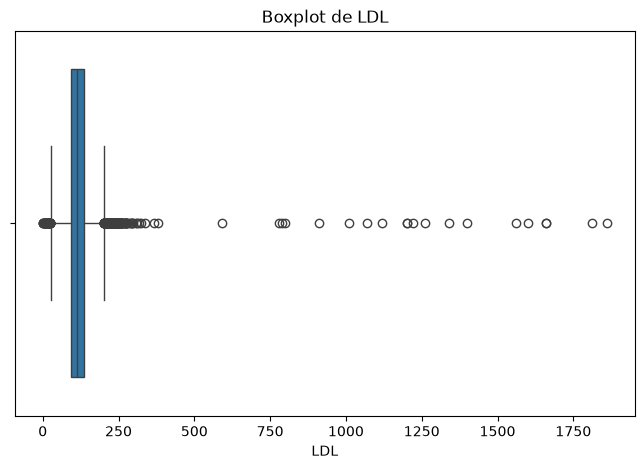

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="LDL")
plt.title("Boxplot de LDL")
plt.show()

In [17]:
df.LDL.describe()

count    50000.000000
mean       114.976740
std         41.021706
min          1.000000
25%         92.000000
50%        113.000000
75%        136.000000
max       1860.000000
Name: LDL, dtype: float64

In [18]:
(df["LDL"] > df["Cholesterol"]).sum() # cuántas personas tienen LDL mayor que el colesterol

np.int64(21)

El LDL llega hasta 1.860, cuando el 75% de las personas tiene 136 o menos. Además, 21 personas tienen el LDL mayor que el colesterol total, lo cual es imposible porque el LDL es una parte del colesterol. Son errores de carga, no valores reales.

In [19]:
(df["eyesight(left)"] == 9.9).sum() # cuántas personas tienen vista 9,9

np.int64(81)

In [20]:
df["eyesight(left)"].value_counts().sort_index() # todos los valores de vista y cuántas veces aparece cada uno

eyesight(left)
0.1      324
0.2      426
0.3      796
0.4     1092
0.5     1899
0.6     2234
0.7     3996
0.8     4758
0.9     4638
1.0    10967
1.1        3
1.2    11363
1.3       10
1.5     7032
1.6       17
1.8        1
1.9        2
2.0      361
9.9       81
Name: count, dtype: int64

La vista va de 0,1 a 2,0 y después salta directo a 9,9, sin valores intermedios. Hay 81 personas con 9,9 en el ojo izquierdo. No es una medida real, sino un código (en este tipo de datos suele indicar ceguera).


In [21]:
df[["triglyceride", "HDL", "AST", "ALT", "Gtp", "fasting blood sugar", "serum creatinine"]].describe(percentiles=[0.5, 0.99]).T

,count,mean,std,min,50%,99%,max
triglyceride,50000.0,126.602660,71.538969,8.0,108.0,361.0,999.0
HDL,50000.0,57.301040,14.773413,4.0,55.0,100.0,618.0
AST,50000.0,26.236640,19.871665,6.0,23.0,80.0,1311.0
ALT,50000.0,27.104280,31.858336,1.0,21.0,111.0,2914.0
Gtp,50000.0,40.035400,50.648321,1.0,25.0,243.0,999.0
fasting blood sugar,50000.0,99.304900,20.782386,46.0,96.0,188.0,505.0
serum creatinine,50000.0,0.885776,0.222783,0.1,0.9,1.3,11.6


El 99% de las personas tiene valores normales, pero el máximo es muchísimo más alto, ALT llega a 2.914 cuando el 99% está debajo de 111. Algunos máximos son 999, que parece el tope del equipo de laboratorio y no una medida real.

#### Matriz de correlación

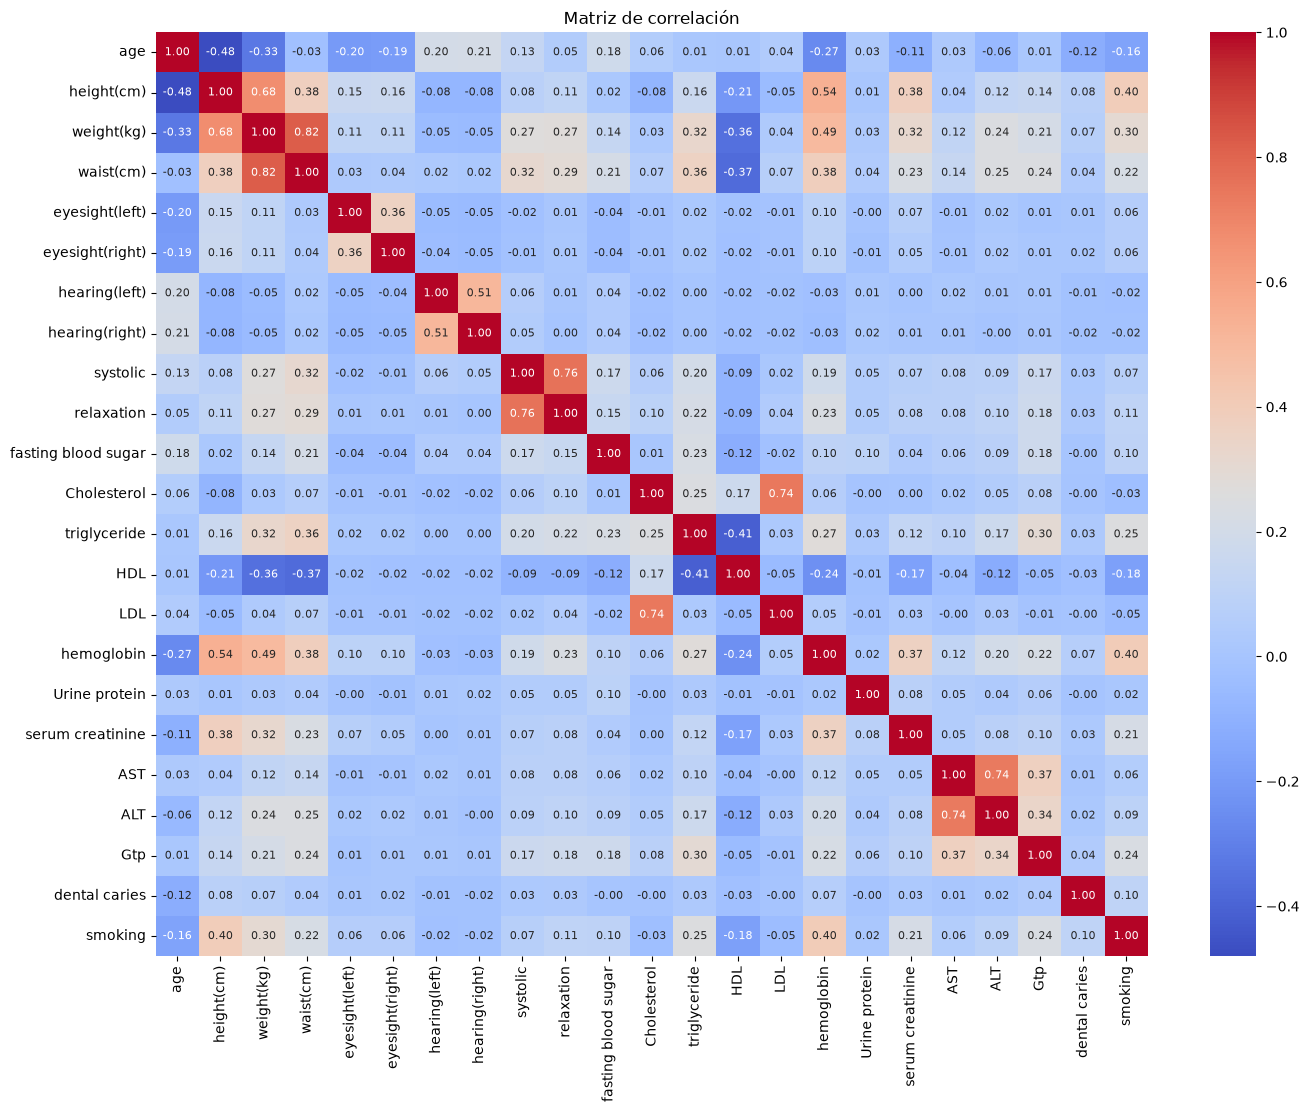

In [22]:
df_corr = df.drop(columns=["ID"]).corr(numeric_only=True)

plt.figure(figsize=(16,12))
sns.heatmap(df_corr, annot=True, cmap="coolwarm", fmt=".2f", annot_kws={"size": 8})
plt.title("Matriz de correlación")
plt.show()

Hay variables muy relacionadas entre sí: peso y cintura (0,82), presión sistólica y diastólica (0,76), colesterol y LDL (0,74), y las enzimas del hígado AST y ALT (0,74). Tiene sentido porque miden cosas parecidas. Con smoking, las más relacionadas siguen siendo hemoglobina, altura y peso, que como vimos tienen que ver con el género.